# Dia 26 — Gerenciamento de Memória em Python & Padrões Eficientes para Data Science

**Fase 1 — Python Basics (Dia 26 de 28)** · 25/11/2026

Este é o caderno de **encerramento técnico da Fase 1**. Depois de estudar profiling e otimização de desempenho (Dia 17), agora o foco é **memória**: como o Python representa objetos, quando eles são liberados e como escrever código de Data Science que não "estoura" a RAM.

### Roteiro
1. Modelo de memória do Python: objetos, referências, `id()` e `sys.getsizeof()`
2. Objetos mutáveis vs imutáveis e suas implicações
3. Coleta de lixo: contagem de referências, `gc` e ciclos
4. O GIL (Global Interpreter Lock) e o que ele significa para DS
5. Padrões eficientes: geradores vs listas, `itertools` para dados grandes
6. Profiling de memória com `tracemalloc`
7. pandas eficiente: downcasting de dtypes e `category`
8. NumPy eficiente: escolha de dtype, *views* vs cópias
9. Aplicação prática: processamento em *chunks* do dataset `diamonds` + corpus textual com geradores
10. Checklist de boas práticas de memória

> **Nota de transparência:** os números de memória dependem da versão do Python, do sistema operacional e das bibliotecas. Os valores mostrados são ilustrativos da execução deste caderno, não *benchmarks* universais.

## 0. Configuração do ambiente

Usamos apenas bibliotecas padrão (`sys`, `gc`, `tracemalloc`, `itertools`, `weakref`) e datasets públicos embutidos no **seaborn** e no **scikit-learn**.

In [1]:
import gc
import io
import re
import sys
import time
import weakref
import itertools
import tracemalloc
import threading
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, ProcessPoolExecutor
from typing import Iterable, Iterator

import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import datasets as skds

print(f"Python  : {sys.version.split()[0]}")
print(f"NumPy   : {np.__version__}")
print(f"pandas  : {pd.__version__}")
print(f"seaborn : {sns.__version__}")


def human_bytes(n: float) -> str:
    """Format a byte count as a human-readable string (B, KB, MB, GB)."""
    for unit in ("B", "KB", "MB", "GB"):
        if abs(n) < 1024:
            return f"{n:,.1f} {unit}"
        n /= 1024
    return f"{n:,.1f} TB"

Python  : 3.11.17
NumPy   : 1.26.4
pandas  : 2.3.3
seaborn : 0.13.2


## 1. O modelo de memória do Python

Em Python, **tudo é objeto**. Uma variável não é uma "caixa" que guarda um valor: ela é um **nome** (um rótulo) que aponta para um objeto que vive no *heap*.

- `id(obj)` → identidade do objeto (no CPython, o endereço de memória).
- `sys.getsizeof(obj)` → tamanho **raso** (*shallow*) do objeto em bytes, sem contar os objetos que ele referencia.
- `is` compara identidade; `==` compara valor.

Uma analogia linguística: o nome da variável é um **significante** e o objeto é o **referente**. Vários significantes (sinônimos) podem apontar para o mesmo referente.

In [2]:
a = [1, 2, 3]
b = a            # b is a second name for the SAME object
c = [1, 2, 3]    # c is a different object with equal value

print(f"id(a) = {id(a)}")
print(f"id(b) = {id(b)}")
print(f"id(c) = {id(c)}")
print(f"a is b -> {a is b} | a == c -> {a == c} | a is c -> {a is c}")

b.append(4)      # mutating through b is visible through a
print(f"a after b.append(4): {a}")

id(a) = 124464733760384
id(b) = 124464733760384
id(c) = 124464733763136
a is b -> True | a == c -> True | a is c -> False
a after b.append(4): [1, 2, 3, 4]


In [3]:
# Shallow sizes of common built-in objects (CPython, 64-bit)
samples = {
    "int 0": 0,
    "int 1": 1,
    "int 2**100": 2**100,
    "float": 3.14,
    "bool": True,
    "None": None,
    "str ''": "",
    "str 'a'": "a",
    "str 'linguistics'": "linguistics",
    "str 'ação' (non-ASCII)": "ação",
    "tuple ()": (),
    "list []": [],
    "dict {}": {},
    "set()": set(),
}
size_table = pd.DataFrame(
    [(name, type(obj).__name__, sys.getsizeof(obj)) for name, obj in samples.items()],
    columns=["object", "type", "getsizeof (bytes)"],
)
size_table

,object,type,getsizeof (bytes)
0,int 0,int,28
1,int 1,int,28
2,int 2**100,int,40
3,float,float,24
4,bool,bool,28
5,None,NoneType,16
6,str '',str,49
7,str 'a',str,50
8,str 'linguistics',str,60
9,str 'ação' (non-ASCII),str,77


### 1.1 `getsizeof` é raso: medindo o tamanho profundo

`sys.getsizeof([...])` mede apenas o "esqueleto" da lista (o array de ponteiros), não as strings ou números dentro dela. Para estimar o tamanho real, precisamos percorrer recursivamente os objetos referenciados, tomando cuidado para **não contar duas vezes** objetos compartilhados.

In [4]:
def deep_getsizeof(obj, seen: set | None = None) -> int:
    """Recursively estimate the memory footprint of an object and its children.

    Objects already visited (by id) are counted only once, so shared
    references and cycles do not inflate the total.
    """
    if seen is None:
        seen = set()
    obj_id = id(obj)
    if obj_id in seen:
        return 0
    seen.add(obj_id)
    size = sys.getsizeof(obj)
    if isinstance(obj, dict):
        size += sum(deep_getsizeof(k, seen) + deep_getsizeof(v, seen) for k, v in obj.items())
    elif isinstance(obj, (list, tuple, set, frozenset)):
        size += sum(deep_getsizeof(item, seen) for item in obj)
    elif hasattr(obj, "__dict__"):
        size += deep_getsizeof(vars(obj), seen)
    return size


words = ["phoneme", "morpheme", "lexeme", "syntax", "semantics", "pragmatics"] * 1000
print(f"Shallow size of the list : {human_bytes(sys.getsizeof(words))}")
print(f"Deep size of the list    : {human_bytes(deep_getsizeof(words))}")
print(f"Unique string objects    : {len({id(w) for w in words})} (literals are shared)")

Shallow size of the list : 46.9 KB
Deep size of the list    : 47.3 KB
Unique string objects    : 6 (literals are shared)


### 1.2 Cache de inteiros pequenos e *interning* de strings

O CPython mantém em cache os inteiros de **-5 a 256** e faz *interning* (reutilização) de muitas strings curtas que parecem identificadores. Isso economiza memória, mas **nunca** devemos usar `is` para comparar valores — é um detalhe de implementação.

Para NLP, `sys.intern()` pode ser útil: num corpus com milhões de *tokens*, mas apenas dezenas de milhares de *types*, internar os tokens faz com que cada palavra repetida aponte para o mesmo objeto.

In [5]:
x, y = 256, 256
print(f"256 is 256 -> {x is y}  (small-int cache)")
x, y = int("257"), int("257")
print(f"257 is 257 -> {x is y}  (created at runtime, not cached)")

# Tokens built at runtime (e.g., from split) are NOT automatically interned
text = " ".join(["teacher student classroom feedback"] * 20_000)
tokens_plain = text.split()
tokens_interned = [sys.intern(t) for t in text.split()]

print(f"\nTokens: {len(tokens_plain):,} | types: {len(set(tokens_plain))}")
print(f"Distinct objects (plain)    : {len({id(t) for t in tokens_plain}):,}")
print(f"Distinct objects (interned) : {len({id(t) for t in tokens_interned}):,}")
print(f"Deep size plain    : {human_bytes(deep_getsizeof(tokens_plain))}")
print(f"Deep size interned : {human_bytes(deep_getsizeof(tokens_interned))}")
del tokens_plain, tokens_interned, text

256 is 256 -> True  (small-int cache)
257 is 257 -> False  (created at runtime, not cached)

Tokens: 80,000 | types: 4
Distinct objects (plain)    : 80,000
Distinct objects (interned) : 4
Deep size plain    : 5.0 MB
Deep size interned : 695.5 KB


## 2. Objetos mutáveis vs imutáveis

| Imutáveis | Mutáveis |
|---|---|
| `int`, `float`, `str`, `tuple`, `frozenset`, `bytes` | `list`, `dict`, `set`, `bytearray`, objetos definidos pelo usuário, `np.ndarray`, `pd.DataFrame` |

Implicações para memória:
- "Modificar" um imutável **cria um novo objeto** (ex.: `s += "x"` em loop gera muitas strings intermediárias).
- Mutáveis podem ser alterados *in place*, mas isso traz o risco de **efeitos colaterais** quando há várias referências (o clássico bug do argumento padrão mutável).
- Tuplas são menores que listas equivalentes porque não reservam espaço extra para crescer.

In [6]:
s = "corpus"
print(f"id before: {id(s)}")
s += "_v2"
print(f"id after : {id(s)}  -> new object created")

lst = [1, 2]
print(f"\nid before: {id(lst)}")
lst += [3]
print(f"id after : {id(lst)}  -> same object mutated in place")

# Tuples vs lists: same content, different footprint
values = list(range(10))
print(f"\nlist  of 10 ints: {sys.getsizeof(values)} bytes")
print(f"tuple of 10 ints: {sys.getsizeof(tuple(values))} bytes")

# Lists over-allocate when they grow (amortized O(1) append)
growth, prev = [], -1
lst = []
for i in range(40):
    size = sys.getsizeof(lst)
    if size != prev:
        growth.append((len(lst), size))
        prev = size
    lst.append(i)
print("\nList capacity jumps (len, bytes):", growth)

id before: 124463249922032
id after : 124463249972720  -> new object created

id before: 124461003540864
id after : 124461003540864  -> same object mutated in place

list  of 10 ints: 136 bytes
tuple of 10 ints: 120 bytes

List capacity jumps (len, bytes): [(0, 56), (1, 88), (5, 120), (9, 184), (17, 248), (25, 312), (33, 376)]


In [7]:
def add_word_bad(word: str, vocab: list = []) -> list:  # noqa: B006 - intentional bug
    """Append a word to a vocabulary list (BUGGY: shared mutable default)."""
    vocab.append(word)
    return vocab


def add_word_good(word: str, vocab: list | None = None) -> list:
    """Append a word to a vocabulary list, creating a fresh list per call."""
    if vocab is None:
        vocab = []
    vocab.append(word)
    return vocab


print("bad :", add_word_bad("hello"), add_word_bad("world"))
print("good:", add_word_good("hello"), add_word_good("world"))

# String building: += in a loop vs str.join
tokens = ["word"] * 50_000
t0 = time.perf_counter()
out = ""
for tok in tokens:
    out += tok + " "
t_concat = time.perf_counter() - t0
t0 = time.perf_counter()
out2 = " ".join(tokens) + " "
t_join = time.perf_counter() - t0
print(f"\n+= loop: {t_concat*1000:.2f} ms | join: {t_join*1000:.2f} ms | equal: {out == out2}")

bad : ['hello', 'world'] ['hello', 'world']
good: ['hello'] ['world']



+= loop: 130.54 ms | join: 0.42 ms | equal: True


### 2.1 Cópia rasa vs cópia profunda

`copy.copy()` duplica apenas o contêiner externo; `copy.deepcopy()` duplica toda a árvore de objetos. Cópias profundas são mais seguras, mas custam memória — use-as só quando necessário.

In [8]:
import copy

nested = {"A1": ["cat", "dog"], "B2": ["although", "whereas"]}
shallow = copy.copy(nested)
deep = copy.deepcopy(nested)

nested["A1"].append("bird")
print(f"original : {nested}")
print(f"shallow  : {shallow}   <- shares inner lists")
print(f"deep     : {deep}   <- fully independent")
print(f"deep size of original: {deep_getsizeof(nested)} B | deep copy adds ~{deep_getsizeof(deep)} B")

original : {'A1': ['cat', 'dog', 'bird'], 'B2': ['although', 'whereas']}
shallow  : {'A1': ['cat', 'dog', 'bird'], 'B2': ['although', 'whereas']}   <- shares inner lists
deep     : {'A1': ['cat', 'dog'], 'B2': ['although', 'whereas']}   <- fully independent
deep size of original: 748 B | deep copy adds ~679 B


### 2.2 `__slots__`: objetos menores

Por padrão, cada instância de classe carrega um `__dict__`. Com `__slots__`, os atributos ficam em posições fixas e o dicionário desaparece — economia significativa quando criamos **milhões** de objetos (ex.: um objeto por token).

In [9]:
class TokenDict:
    """Token record using a regular per-instance __dict__."""

    def __init__(self, text: str, pos: str, position: int):
        self.text = text
        self.pos = pos
        self.position = position


class TokenSlots:
    """Token record using __slots__ (no per-instance __dict__)."""

    __slots__ = ("text", "pos", "position")

    def __init__(self, text: str, pos: str, position: int):
        self.text = text
        self.pos = pos
        self.position = position


def measure_peak(func, *args, **kwargs):
    """Run func and return (result, peak_bytes) measured with tracemalloc."""
    gc.collect()
    tracemalloc.start()
    result = func(*args, **kwargs)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return result, peak


N = 200_000
_, peak_dict = measure_peak(lambda: [TokenDict("word", "NOUN", i) for i in range(N)])
_, peak_slots = measure_peak(lambda: [TokenSlots("word", "NOUN", i) for i in range(N)])
print(f"{N:,} TokenDict  objects: {human_bytes(peak_dict)}")
print(f"{N:,} TokenSlots objects: {human_bytes(peak_slots)}")
print(f"Savings: {(1 - peak_slots / peak_dict):.0%}")

200,000 TokenDict  objects: 26.0 MB
200,000 TokenSlots objects: 18.3 MB
Savings: 29%


## 3. Coleta de lixo (Garbage Collection)

O CPython libera memória por dois mecanismos complementares:

1. **Contagem de referências** — cada objeto sabe quantas referências apontam para ele. Quando a contagem chega a zero, ele é liberado **imediatamente**. `sys.getrefcount()` mostra esse número (sempre +1, pela referência temporária do próprio argumento).
2. **Coletor cíclico (`gc`)** — detecta grupos de objetos que se referenciam mutuamente (ciclos) e que não são mais acessíveis. Funciona por **gerações** (0, 1, 2): objetos novos são verificados com mais frequência.

In [10]:
data = ["a", "b"]
print(f"refcount after creation       : {sys.getrefcount(data)}")
alias = data
container = {"key": data}
print(f"refcount with alias + dict ref: {sys.getrefcount(data)}")
del alias
container.clear()
print(f"refcount after removing refs  : {sys.getrefcount(data)}")

print(f"\nGC thresholds (gen0, gen1, gen2): {gc.get_threshold()}")
print(f"Objects pending per generation : {gc.get_count()}")
print(f"GC enabled                     : {gc.isenabled()}")

refcount after creation       : 2
refcount with alias + dict ref: 4
refcount after removing refs  : 2

GC thresholds (gen0, gen1, gen2): (700, 10, 10)
Objects pending per generation : (287, 8, 11)
GC enabled                     : True


In [11]:
class Node:
    """Simple graph node that can form reference cycles."""

    def __init__(self, name: str):
        self.name = name
        self.partner = None


def create_cycles(n: int) -> None:
    """Create n two-node reference cycles and drop all external references."""
    for i in range(n):
        a, b = Node(f"a{i}"), Node(f"b{i}")
        a.partner, b.partner = b, a  # cycle: refcount never reaches zero alone


gc.collect()
gc.disable()  # disable automatic GC to make the effect visible
create_cycles(10_000)
alive_before = sum(isinstance(o, Node) for o in gc.get_objects())
collected = gc.collect()
alive_after = sum(isinstance(o, Node) for o in gc.get_objects())
gc.enable()

print(f"Node objects alive before gc.collect(): {alive_before:,}")
print(f"Objects collected by the cyclic GC    : {collected:,}")
print(f"Node objects alive after gc.collect() : {alive_after:,}")

Node objects alive before gc.collect(): 20,000
Objects collected by the cyclic GC    : 20,000
Node objects alive after gc.collect() : 0


### 3.1 Referências fracas (`weakref`)

Um **cache** que guarda referências fortes impede que os objetos sejam liberados. Com `weakref`, o cache não "segura" o objeto: quando ninguém mais o usa, ele é coletado e a entrada desaparece sozinha. Útil para caches de modelos ou de documentos processados.

In [12]:
class Document:
    """A processed document stored in a cache."""

    def __init__(self, doc_id: str, text: str):
        self.doc_id = doc_id
        self.text = text


cache = weakref.WeakValueDictionary()
doc = Document("iris_descr", skds.load_iris().DESCR)
cache[doc.doc_id] = doc
print(f"Cache keys while doc is referenced: {list(cache.keys())}")

ref = weakref.ref(doc)
print(f"Weak ref resolves to: {ref().doc_id}")

del doc
gc.collect()
print(f"Cache keys after `del doc`        : {list(cache.keys())}")
print(f"Weak ref now returns              : {ref()}")

Cache keys while doc is referenced: ['iris_descr']
Weak ref resolves to: iris_descr
Cache keys after `del doc`        : []
Weak ref now returns              : None


### 3.2 Liberando memória em notebooks

Em Jupyter, objetos grandes podem continuar vivos por causa de referências escondidas: `_`, `__`, `Out[n]` e variáveis de loop. Boas práticas:
- `del df_grande` quando não precisar mais;
- evitar deixar um DataFrame enorme como última expressão de uma célula (ele vai para `Out`);
- `gc.collect()` depois de remover estruturas com ciclos;
- lembrar que o processo nem sempre devolve a memória ao sistema operacional imediatamente (o alocador do Python reutiliza os blocos).

## 4. O GIL (Global Interpreter Lock)

O **GIL** é um *lock* do CPython que garante que apenas **uma thread execute bytecode Python por vez**. Ele existe principalmente para proteger a contagem de referências (seção 3) de condições de corrida.

Implicações práticas para DS:

| Tipo de tarefa | Threads ajudam? | Por quê |
|---|---|---|
| Código Python puro, CPU-bound (loops) | ❌ Não | O GIL serializa a execução |
| I/O (APIs, arquivos, banco de dados) | ✅ Sim | O GIL é liberado enquanto espera I/O |
| NumPy / pandas / scikit-learn vetorizados | ✅ Muitas vezes | Código em C costuma liberar o GIL |
| CPU-bound em Python puro | ✅ Use processos | Cada processo tem seu próprio GIL (mas copia memória!) |

> Desde o Python 3.13 existe uma build experimental *free-threaded* (PEP 703) sem GIL, ainda não padrão. A concorrência em si foi estudada no Dia 14; aqui o foco é o **custo de memória**: processos duplicam dados, threads compartilham.

In [13]:
def cpu_bound_python(n: int) -> int:
    """Pure-Python CPU-bound work (holds the GIL)."""
    total = 0
    for i in range(n):
        total += i * i
    return total


def numpy_bound(n: int) -> float:
    """NumPy work that runs in C and can release the GIL."""
    arr = np.arange(n, dtype=np.float64)
    return float(np.sqrt(arr).sum())


def timed(label: str, func, jobs: int, n: int, workers: int | None = None) -> float:
    """Time `jobs` calls of func sequentially (workers=None) or with a thread pool."""
    t0 = time.perf_counter()
    if workers is None:
        for _ in range(jobs):
            func(n)
    else:
        with ThreadPoolExecutor(max_workers=workers) as ex:
            list(ex.map(func, [n] * jobs))
    elapsed = time.perf_counter() - t0
    print(f"{label:<32}: {elapsed:.3f} s")
    return elapsed


print(f"Active threads: {threading.active_count()}")
t_seq = timed("Pure Python, sequential", cpu_bound_python, 4, 1_000_000)
t_thr = timed("Pure Python, 4 threads", cpu_bound_python, 4, 1_000_000, workers=4)
print(f"  -> threads speedup: {t_seq / t_thr:.2f}x (≈1x or worse because of the GIL)\n")
n_seq = timed("NumPy, sequential", numpy_bound, 4, 5_000_000)
n_thr = timed("NumPy, 4 threads", numpy_bound, 4, 5_000_000, workers=4)
print(f"  -> threads speedup: {n_seq / n_thr:.2f}x (can be >1x: C code may release the GIL)")
print("\nTimings are machine-dependent; the qualitative contrast is what matters.")

Active threads: 8


Pure Python, sequential         : 0.170 s


Pure Python, 4 threads          : 0.167 s
  -> threads speedup: 1.02x (≈1x or worse because of the GIL)



NumPy, sequential               : 0.164 s


NumPy, 4 threads                : 0.059 s
  -> threads speedup: 2.77x (can be >1x: C code may release the GIL)

Timings are machine-dependent; the qualitative contrast is what matters.


## 5. Padrões eficientes: geradores vs listas

Uma **lista** materializa todos os elementos na memória. Um **gerador** produz um elemento por vez, sob demanda (*lazy evaluation*). Para pipelines que só precisam percorrer os dados uma vez (somar, contar, filtrar, escrever em disco), geradores mantêm a memória **constante**, independentemente do tamanho da entrada.

In [14]:
N = 1_000_000
squares_list = [i * i for i in range(N)]
squares_gen = (i * i for i in range(N))

print(f"List of {N:,} squares (shallow): {human_bytes(sys.getsizeof(squares_list))}")
print(f"Generator object               : {sys.getsizeof(squares_gen)} bytes")

_, peak_list = measure_peak(lambda: sum([i * i for i in range(N)]))
_, peak_gen = measure_peak(lambda: sum(i * i for i in range(N)))
print(f"\nPeak memory sum(list comprehension): {human_bytes(peak_list)}")
print(f"Peak memory sum(generator expr)    : {human_bytes(peak_gen)}")
del squares_list

List of 1,000,000 squares (shallow): 8.1 MB
Generator object               : 208 bytes



Peak memory sum(list comprehension): 38.6 MB
Peak memory sum(generator expr)    : 568.0 B


In [15]:
def read_lines(text: str) -> Iterator[str]:
    """Yield lines lazily from a text buffer (simulates reading a large file)."""
    with io.StringIO(text) as fh:
        for line in fh:
            yield line.rstrip("\n")


def parse_rows(lines: Iterable[str]) -> Iterator[list[str]]:
    """Split CSV lines into fields, skipping the header."""
    lines = iter(lines)
    next(lines)  # skip header
    for line in lines:
        yield line.split(",")


def filter_price(rows: Iterable[list[str]], min_price: float) -> Iterator[float]:
    """Yield prices above a threshold (price is the 7th column in diamonds)."""
    for row in rows:
        price = float(row[6])
        if price >= min_price:
            yield price


diamonds_csv = sns.load_dataset("diamonds").to_csv(index=False)
pipeline = filter_price(parse_rows(read_lines(diamonds_csv)), min_price=10_000)
count, total = 0, 0.0
for price in pipeline:  # each row flows through all stages one at a time
    count += 1
    total += price
print(f"Diamonds priced >= $10,000: {count:,} | mean price: ${total / count:,.2f}")

Diamonds priced >= $10,000: 5,223 | mean price: $13,639.76


### 5.1 `itertools` para dados grandes

`itertools` (estudado em profundidade no Dia 12) é a caixa de ferramentas natural para memória constante. Aqui o foco são os padrões **orientados à memória**:
- `islice` → "espiar" ou paginar um fluxo sem materializá-lo;
- `batched` (3.12+) ou uma alternativa com `islice` → processar em lotes de tamanho fixo;
- `chain.from_iterable` → concatenar muitas fontes sem criar uma lista gigante;
- `groupby` → agregar dados **já ordenados** em streaming.

In [16]:
def batched_compat(iterable: Iterable, n: int) -> Iterator[tuple]:
    """Yield successive n-sized tuples (fallback for itertools.batched on < 3.12)."""
    it = iter(iterable)
    while batch := tuple(itertools.islice(it, n)):
        yield batch


batched = getattr(itertools, "batched", batched_compat)

stream = (i * 2 for i in range(10**9))  # a "billion-row" stream: never materialized
print("First 5 items via islice:", list(itertools.islice(stream, 5)))

batch_means = [round(sum(b) / len(b), 1) for b in itertools.islice(batched(range(1, 101), 25), 4)]
print("Means of 4 batches of 25:", batch_means)

sources = [skds.load_iris().DESCR, skds.load_wine().DESCR, skds.load_breast_cancer().DESCR]
all_lines = itertools.chain.from_iterable(s.splitlines() for s in sources)
print("Total DESCR lines (streamed):", sum(1 for _ in all_lines))

# Streaming group-by on sorted data: mean diamond price per cut
rows = sorted(
    ((r.cut, r.price) for r in sns.load_dataset("diamonds").itertuples(index=False)),
    key=lambda t: str(t[0]),
)
for cut, group in itertools.groupby(rows, key=lambda t: t[0]):
    n, s = 0, 0
    for _, price in group:
        n += 1
        s += price
    print(f"  {cut:<10} n={n:>6,}  mean=${s / n:,.0f}")

First 5 items via islice: [0, 2, 4, 6, 8]
Means of 4 batches of 25: [13.0, 38.0, 63.0, 88.0]
Total DESCR lines (streamed): 275


  Fair       n= 1,610  mean=$4,359
  Good       n= 4,906  mean=$3,929
  Ideal      n=21,551  mean=$3,458
  Premium    n=13,791  mean=$4,584
  Very Good  n=12,082  mean=$3,982


## 6. Profiling de memória com `tracemalloc`

`tracemalloc` é um módulo **da biblioteca padrão** que rastreia alocações feitas pelo Python. Principais recursos:
- `start()` / `stop()` → liga e desliga o rastreamento;
- `get_traced_memory()` → `(atual, pico)` em bytes;
- `take_snapshot()` + `statistics("lineno")` → quais linhas alocaram mais;
- `snapshot.compare_to(outro, ...)` → diferença entre dois momentos (ótimo para achar vazamentos).

> Limitação: ele só enxerga alocações feitas pelo alocador do Python. NumPy registra seus buffers no `tracemalloc`, então arrays aparecem; mas bibliotecas C que usam alocadores próprios podem não aparecer.

In [17]:
from contextlib import contextmanager


@contextmanager
def memory_tracker(label: str):
    """Context manager that reports current and peak memory traced in its block."""
    gc.collect()
    tracemalloc.start()
    t0 = time.perf_counter()
    try:
        yield
    finally:
        current, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        print(f"[{label}] current={human_bytes(current)} | peak={human_bytes(peak)} "
              f"| time={time.perf_counter() - t0:.3f}s")


with memory_tracker("list of 500k floats"):
    floats = [float(i) for i in range(500_000)]

with memory_tracker("numpy array of 500k float64"):
    arr = np.arange(500_000, dtype=np.float64)

with memory_tracker("numpy array of 500k float32"):
    arr32 = np.arange(500_000, dtype=np.float32)

del floats, arr, arr32

[list of 500k floats] current=15.4 MB | peak=15.4 MB | time=0.336s
[numpy array of 500k float64] current=3.8 MB | peak=3.8 MB | time=0.000s
[numpy array of 500k float32] current=1.9 MB | peak=1.9 MB | time=0.000s


In [18]:
def build_vocab_naive(texts: list[str]) -> dict[str, int]:
    """Build a word-frequency dict by materializing every token list."""
    all_tokens = []
    for t in texts:
        all_tokens.extend(re.findall(r"[a-z]+", t.lower()))
    counts: dict[str, int] = {}
    for tok in all_tokens:
        counts[tok] = counts.get(tok, 0) + 1
    return counts


corpus_texts = [
    getattr(skds, loader)().DESCR
    for loader in ("load_iris", "load_wine", "load_breast_cancer", "load_diabetes", "load_digits")
] * 40  # repeat to make the effect measurable

gc.collect()
tracemalloc.start()
snap_before = tracemalloc.take_snapshot()
vocab = build_vocab_naive(corpus_texts)
snap_after = tracemalloc.take_snapshot()
tracemalloc.stop()

print(f"Vocabulary size: {len(vocab):,}\nTop allocation differences by line:")
for stat in snap_after.compare_to(snap_before, "lineno")[:5]:
    print("  ", stat)

Vocabulary size: 606
Top allocation differences by line:
   /opt/computersetup/.pyenv/versions/3.11.17/lib/python3.11/re/__init__.py:216: size=31.5 KiB (+31.5 KiB), count=582 (+582), average=55 B
   /tmp/ipykernel_1014/220776188.py:8: size=13.8 KiB (+13.8 KiB), count=38 (+38), average=373 B
   /opt/computersetup/.pyenv/versions/3.11.17/lib/python3.11/codeop.py:125: size=805 B (+384 B), count=11 (+7), average=73 B
   /opt/computersetup/.pyenv/versions/3.11.17/lib/python3.11/tracemalloc.py:560: size=320 B (+320 B), count=2 (+2), average=160 B
   /opt/computersetup/.pyenv/versions/3.11.17/lib/python3.11/tracemalloc.py:423: size=320 B (+320 B), count=2 (+2), average=160 B


## 7. pandas eficiente: otimização de dtypes

Por padrão, o pandas usa `int64`, `float64` e `object` (strings como objetos Python). Na maioria dos datasets, isso é desperdício:

| dtype | Bytes/valor | Faixa |
|---|---|---|
| `int8` | 1 | -128 a 127 |
| `int16` | 2 | -32.768 a 32.767 |
| `int32` | 4 | ±2,1 bilhões |
| `float32` | 4 | ~7 dígitos de precisão |
| `float64` | 8 | ~15 dígitos |
| `category` | códigos inteiros + categorias únicas | ideal para baixa cardinalidade |

Sempre use `df.memory_usage(deep=True)` — sem `deep=True`, colunas `object` são subestimadas.

In [19]:
titanic = sns.load_dataset("titanic")
# Make every text-like column a plain object column (the "naive" default)
for col in titanic.select_dtypes(include=["category", "string"]).columns:
    titanic[col] = titanic[col].astype(object)

print(titanic.dtypes.value_counts().to_string())
print(f"\nShallow memory: {human_bytes(titanic.memory_usage().sum())}")
print(f"Deep memory   : {human_bytes(titanic.memory_usage(deep=True).sum())}")
titanic.memory_usage(deep=True).sort_values(ascending=False).head(8).to_frame("bytes")

object     7
int64      4
float64    2
bool       2

Shallow memory: 92.4 KB
Deep memory   : 398.1 KB


,bytes
embark_town,60103
class,55426
sex,54979
who,54168
alive,52911
embarked,51626
deck,33790
survived,7128


In [20]:
def optimize_dtypes(df: pd.DataFrame, cat_threshold: float = 0.5,
                    float_precision: str = "float32") -> pd.DataFrame:
    """Return a memory-optimized copy of df.

    - integers are downcast to the smallest signed/unsigned type that fits;
    - floats are downcast to float32 (may lose precision beyond ~7 digits);
    - object columns whose unique ratio is below cat_threshold become 'category'.
    """
    out = df.copy()
    for col in out.columns:
        s = out[col]
        if pd.api.types.is_bool_dtype(s):
            continue
        if pd.api.types.is_integer_dtype(s):
            kind = "unsigned" if s.min() >= 0 else "integer"
            out[col] = pd.to_numeric(s, downcast=kind)
        elif pd.api.types.is_float_dtype(s):
            out[col] = s.astype(float_precision)
        elif s.dtype == object:
            if s.nunique(dropna=True) / max(len(s), 1) < cat_threshold:
                out[col] = s.astype("category")
    return out


def memory_report(before: pd.DataFrame, after: pd.DataFrame) -> pd.DataFrame:
    """Compare per-column deep memory usage and dtypes before/after optimization."""
    rep = pd.DataFrame({
        "dtype_before": before.dtypes.astype(str),
        "dtype_after": after.dtypes.astype(str),
        "bytes_before": before.memory_usage(deep=True, index=False),
        "bytes_after": after.memory_usage(deep=True, index=False),
    })
    rep["saving_%"] = (1 - rep["bytes_after"] / rep["bytes_before"]).mul(100).round(1)
    return rep.sort_values("bytes_before", ascending=False)


titanic_opt = optimize_dtypes(titanic)
b, a = titanic.memory_usage(deep=True).sum(), titanic_opt.memory_usage(deep=True).sum()
print(f"Titanic: {human_bytes(b)} -> {human_bytes(a)} ({1 - a / b:.1%} smaller)")
memory_report(titanic, titanic_opt)

Titanic: 398.1 KB -> 20.7 KB (94.8% smaller)


,dtype_before,dtype_after,bytes_before,bytes_after,saving_%
embark_town,object,category,60103,1200,98.0
class,object,category,55426,1186,97.9
sex,object,category,54979,1123,98.0
who,object,category,54168,1183,97.8
alive,object,category,52911,1118,97.9
embarked,object,category,51626,1173,97.7
deck,object,category,33790,1597,95.3
fare,float64,float32,7128,3564,50.0
parch,int64,uint8,7128,891,87.5
sibsp,int64,uint8,7128,891,87.5


### 7.1 O dtype `category` em detalhe

Uma coluna `category` guarda **um inteiro pequeno por linha** (os *codes*) e a lista de valores únicos **uma só vez** (as *categories*). É como um dicionário de *types* com índices para cada *token*. Cuidados:
- vale a pena quando a cardinalidade é baixa em relação ao número de linhas;
- `groupby` em categóricas: use `observed=True` para não gerar combinações vazias;
- concatenar categóricas com categorias diferentes pode voltar a `object`.

In [21]:
diamonds = sns.load_dataset("diamonds")
cut_obj = diamonds["cut"].astype(object)
cut_cat = cut_obj.astype("category")

print(f"cut as object  : {human_bytes(cut_obj.memory_usage(deep=True))}")
print(f"cut as category: {human_bytes(cut_cat.memory_usage(deep=True))}")
print(f"codes dtype    : {cut_cat.cat.codes.dtype} | categories: {list(cut_cat.cat.categories)}")

# Performance bonus: groupby on category vs object
t0 = time.perf_counter(); diamonds.assign(cut=cut_obj).groupby("cut")["price"].mean(); t_obj = time.perf_counter() - t0
t0 = time.perf_counter(); diamonds.assign(cut=cut_cat).groupby("cut", observed=True)["price"].mean(); t_cat = time.perf_counter() - t0
print(f"groupby mean - object: {t_obj*1000:.2f} ms | category: {t_cat*1000:.2f} ms")

# Pitfall: high-cardinality column -> category can be WORSE
ids = pd.Series([f"id_{i}" for i in range(len(diamonds))])
print(f"\nUnique IDs as object  : {human_bytes(ids.memory_usage(deep=True))}")
print(f"Unique IDs as category: {human_bytes(ids.astype('category').memory_usage(deep=True))}  <- no gain")

cut as object  : 3.3 MB
cut as category: 53.3 KB
codes dtype    : int8 | categories: ['Fair', 'Good', 'Ideal', 'Premium', 'Very Good']
groupby mean - object: 2.79 ms | category: 1.47 ms

Unique IDs as object  : 3.3 MB
Unique IDs as category: 5.6 MB  <- no gain


In [22]:
# Optimizing at load time: declare dtypes in read_csv (avoids the int64/float64/object peak)
penguins = sns.load_dataset("penguins")
csv_buffer = penguins.to_csv(index=False)

dtype_map = {
    "species": "category", "island": "category", "sex": "category",
    "bill_length_mm": "float32", "bill_depth_mm": "float32",
    "flipper_length_mm": "float32", "body_mass_g": "float32",
}
with memory_tracker("read_csv default dtypes"):
    p_default = pd.read_csv(io.StringIO(csv_buffer))
with memory_tracker("read_csv with dtype map"):
    p_typed = pd.read_csv(io.StringIO(csv_buffer), dtype=dtype_map)

print(f"\nDefault : {human_bytes(p_default.memory_usage(deep=True).sum())}")
print(f"Typed   : {human_bytes(p_typed.memory_usage(deep=True).sum())}")

# Precision check: float32 keeps ~7 significant digits — fine for these measurements
max_err = (p_default["body_mass_g"] - p_typed["body_mass_g"].astype("float64")).abs().max()
print(f"Max abs error from float32 on body_mass_g: {max_err}")

[read_csv default dtypes] current=29.7 KB | peak=143.7 KB | time=0.003s


[read_csv with dtype map] current=35.3 KB | peak=128.5 KB | time=0.007s

Default : 73.9 KB
Typed   : 7.2 KB
Max abs error from float32 on body_mass_g: 0.0


## 8. NumPy eficiente: dtypes, *views* e cópias

Um `ndarray` é um bloco **contíguo** de memória com metadados (shape, strides, dtype). Duas alavancas principais:

1. **Escolha de dtype** → `nbytes = n_elementos × itemsize`.
2. ***Views* vs cópias** → *slicing* básico, `reshape` (quando possível), `.T` e `.view()` retornam **views** (compartilham o buffer, custo ~zero). *Fancy indexing*, máscaras booleanas, `.copy()` e operações aritméticas criam **cópias**.

Use `np.shares_memory(a, b)` ou `arr.base` para verificar.

In [23]:
n = 1_000_000
dtype_rows = []
for dt in (np.int8, np.int16, np.int32, np.int64, np.float16, np.float32, np.float64, np.bool_):
    arr = np.zeros(n, dtype=dt)
    dtype_rows.append((np.dtype(dt).name, arr.itemsize, arr.nbytes,
                       str(np.iinfo(dt).max) if np.issubdtype(dt, np.integer) else "-"))
pd.DataFrame(dtype_rows, columns=["dtype", "itemsize", "nbytes (1M elements)", "int max"])

,dtype,itemsize,nbytes (1M elements),int max
0,int8,1,1000000,127
1,int16,2,2000000,32767
2,int32,4,4000000,2147483647
3,int64,8,8000000,9223372036854775807
4,float16,2,2000000,-
5,float32,4,4000000,-
6,float64,8,8000000,-
7,bool,1,1000000,-


In [24]:
X = skds.load_breast_cancer().data  # float64, shape (569, 30)
print(f"breast_cancer X: shape={X.shape}, dtype={X.dtype}, nbytes={human_bytes(X.nbytes)}")

view_slice = X[:100, :5]          # basic slicing -> view
view_T = X.T                      # transpose -> view
copy_fancy = X[[0, 1, 2], :]      # fancy indexing -> copy
copy_mask = X[X[:, 0] > 15]       # boolean mask -> copy
X32 = X.astype(np.float32)        # astype -> copy with new dtype

for name, obj in [("X[:100, :5]", view_slice), ("X.T", view_T), ("X[[0,1,2], :]", copy_fancy),
                  ("X[X[:,0] > 15]", copy_mask), ("X.astype(float32)", X32)]:
    print(f"{name:<20} shares memory with X: {str(np.shares_memory(X, obj)):<5} | "
          f"base is X: {obj.base is X}")

print(f"\nfloat32 version: {human_bytes(X32.nbytes)} "
      f"(max relative error {np.max(np.abs(X32 - X) / np.maximum(np.abs(X), 1e-12)):.2e})")

breast_cancer X: shape=(569, 30), dtype=float64, nbytes=133.4 KB
X[:100, :5]          shares memory with X: True  | base is X: True
X.T                  shares memory with X: True  | base is X: True
X[[0,1,2], :]        shares memory with X: False | base is X: False
X[X[:,0] > 15]       shares memory with X: False | base is X: False
X.astype(float32)    shares memory with X: False | base is X: False

float32 version: 66.7 KB (max relative error 5.88e-08)


In [25]:
# Views are powerful but dangerous: modifying a view modifies the original
original = np.arange(10)
window = original[2:5]
window[:] = -1
print(f"original after editing the view: {original}")

# In-place operations avoid temporary arrays
big = np.random.default_rng(42).random(2_000_000)

with memory_tracker("out-of-place: y = big * 2 + 1"):
    y = big * 2 + 1                   # creates temporaries
with memory_tracker("in-place: big *= 2; big += 1"):
    big *= 2
    big += 1                          # reuses the existing buffer
print(f"Results equal: {np.allclose(y, big)}")

# np.add with out= also writes into a pre-allocated buffer
buf = np.empty_like(big)
with memory_tracker("np.multiply(big, 0.5, out=buf)"):
    np.multiply(big, 0.5, out=buf)
del y, big, buf

original after editing the view: [ 0  1 -1 -1 -1  5  6  7  8  9]


[out-of-place: y = big * 2 + 1] current=15.3 MB | peak=15.3 MB | time=0.003s
[in-place: big *= 2; big += 1] current=0.0 B | peak=208.0 B | time=0.002s
Results equal: True
[np.multiply(big, 0.5, out=buf)] current=192.0 B | peak=296.0 B | time=0.002s


### 8.1 `memmap`: arrays maiores que a RAM

`np.memmap` mapeia um arquivo binário em disco como se fosse um array. O sistema operacional carrega apenas as páginas acessadas — uma forma simples de trabalhar com matrizes maiores que a memória disponível.

In [26]:
import os
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    path = os.path.join(tmp, "diamonds_numeric.dat")
    numeric_df = sns.load_dataset("diamonds").select_dtypes("number")
    price_idx = numeric_df.columns.get_loc("price")
    numeric = numeric_df.to_numpy(dtype=np.float32)

    mm = np.memmap(path, dtype=np.float32, mode="w+", shape=numeric.shape)
    mm[:] = numeric
    mm.flush()
    del mm

    with memory_tracker("open memmap + column mean"):
        ro = np.memmap(path, dtype=np.float32, mode="r", shape=numeric.shape)
        price_mean = float(ro[:, price_idx].mean())   # only the needed pages are read
    print(f"File size: {human_bytes(os.path.getsize(path))} | mean price: ${price_mean:,.2f}")
    del ro

[open memmap + column mean] current=1.7 KB | peak=6.1 KB | time=0.001s
File size: 1.4 MB | mean price: $3,932.80


## 9. Aplicação prática: processamento eficiente de um dataset "grande"

Vamos simular um cenário real: o dataset `diamonds` (53.940 linhas) replicado **10×** (~540 mil linhas) e salvo como CSV. Compararemos duas abordagens para calcular estatísticas por `cut` e `color`:

- **Abordagem ingênua:** `read_csv` com dtypes padrão e tudo na memória.
- **Abordagem eficiente:** `usecols` + `dtype` + leitura em *chunks*, agregando incrementalmente.

In [27]:
base = sns.load_dataset("diamonds")
big_df = pd.concat([base] * 10, ignore_index=True)

tmp_dir = tempfile.mkdtemp(prefix="day26_")
big_csv = os.path.join(tmp_dir, "diamonds_x10.csv")
big_df.to_csv(big_csv, index=False)
print(f"Rows: {len(big_df):,} | CSV size on disk: {human_bytes(os.path.getsize(big_csv))}")
del big_df, base
gc.collect()

Rows: 539,400 | CSV size on disk: 24.5 MB


0

In [28]:
def naive_stats(path: str) -> pd.DataFrame:
    """Load the whole CSV with default dtypes and aggregate."""
    df = pd.read_csv(path)
    return df.groupby(["cut", "color"])["price"].agg(["count", "sum"])


def chunked_stats(path: str, chunksize: int = 50_000) -> pd.DataFrame:
    """Aggregate price by cut/color reading only needed columns in typed chunks."""
    partials = []
    reader = pd.read_csv(
        path,
        usecols=["cut", "color", "price"],
        dtype={"cut": "category", "color": "category", "price": "int32"},
        chunksize=chunksize,
    )
    for chunk in reader:
        partials.append(chunk.groupby(["cut", "color"], observed=True)["price"].agg(["count", "sum"]))
    return pd.concat(partials).groupby(level=[0, 1], observed=True).sum()


def normalize_result(res: pd.DataFrame) -> pd.DataFrame:
    """Cast index labels to str and values to int64 so both approaches compare cleanly."""
    out = res.reset_index()
    out[["cut", "color"]] = out[["cut", "color"]].astype(str)
    return out.astype({"count": "int64", "sum": "int64"}).sort_values(["cut", "color"]).reset_index(drop=True)


gc.collect()
res_naive, peak_naive = measure_peak(naive_stats, big_csv)
res_chunk, peak_chunk = measure_peak(chunked_stats, big_csv)

same = normalize_result(res_naive).equals(normalize_result(res_chunk))
print(f"Naive   peak memory: {human_bytes(peak_naive)}")
print(f"Chunked peak memory: {human_bytes(peak_chunk)}")
print(f"Reduction: {1 - peak_chunk / peak_naive:.1%} | identical results: {same}")

Naive   peak memory: 131.7 MB
Chunked peak memory: 3.5 MB
Reduction: 97.4% | identical results: True


In [29]:
summary = res_chunk.assign(mean_price=lambda d: (d["sum"] / d["count"]).round(0))
pivot = summary["mean_price"].unstack("color")
pivot

color,D,E,F,G,H,I,J
cut,,,,,,,
Fair,4291.0,3682.0,3827.0,4239.0,5136.0,4685.0,4976.0
Good,3405.0,3424.0,3496.0,4123.0,4276.0,5079.0,4574.0
Ideal,2629.0,2598.0,3375.0,3721.0,3889.0,4452.0,4918.0
Premium,3631.0,3539.0,4325.0,4501.0,5217.0,5946.0,6295.0
Very Good,3470.0,3215.0,3779.0,3873.0,4535.0,5256.0,5104.0


### 9.1 Matrizes de features mais leves para o scikit-learn

Muitos estimadores do scikit-learn aceitam `float32`. Converter as features **antes** de treinar reduz a memória pela metade — mas atenção: alguns estimadores convertem internamente para `float64` de qualquer forma (gerando uma cópia). Aqui comparamos `LogisticRegression` no `load_wine` com `float64` e `float32`.

In [30]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_w, y_w = skds.load_wine(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X_w, y_w, test_size=0.3, random_state=42, stratify=y_w)
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

results = []
for dt in (np.float64, np.float32):
    Xtr, Xte = X_tr_s.astype(dt), X_te_s.astype(dt)
    model = LogisticRegression(max_iter=1000).fit(Xtr, y_tr)
    results.append({
        "dtype": np.dtype(dt).name,
        "X_train nbytes": Xtr.nbytes,
        "coef dtype": model.coef_.dtype.name,
        "test accuracy": round(model.score(Xte, y_te), 4),
    })
pd.DataFrame(results)

,dtype,X_train nbytes,coef dtype,test accuracy
0,float64,12896,float64,0.9815
1,float32,6448,float32,0.9815


### 9.2 Ângulo linguístico: processamento de corpus palavra por palavra

Em NLP, corpora reais (ex.: redações de alunos, transcrições de aulas) podem ter milhões de *tokens*. Carregar tudo como listas de listas de strings é caro. O padrão eficiente é um **pipeline de geradores**:

`documentos → frases → tokens → normalização → contagem incremental (Counter)`

Como corpus usamos a documentação real (`DESCR`) dos datasets do scikit-learn — textos acadêmicos em inglês sobre os próprios dados. Ao final, calculamos estatísticas sociolinguisticamente relevantes: *tokens*, *types*, TTR e uma distribuição de frequência (lei de Zipf). As faixas de frequência são heurísticas, **não** níveis do CEFR.

In [31]:
CORPUS_LOADERS = ("load_iris", "load_wine", "load_breast_cancer", "load_diabetes",
                  "load_digits", "load_linnerud")
STOPWORDS = frozenset("""
a an and are as at be by for from has have in is it its of on or that the this to was were
which with these those their there been can not no all also than other into each per
""".split())
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?")


def iter_documents(repeat: int = 1) -> Iterator[tuple[str, str]]:
    """Yield (doc_id, text) pairs from scikit-learn dataset descriptions, lazily."""
    for r in range(repeat):
        for loader in CORPUS_LOADERS:
            yield f"{loader}#{r}", getattr(skds, loader)().DESCR


def iter_tokens(docs: Iterable[tuple[str, str]]) -> Iterator[str]:
    """Yield lowercase word tokens one by one, line by line (constant memory)."""
    for _, text in docs:
        for line in text.splitlines():
            for match in TOKEN_RE.finditer(line.lower()):
                yield sys.intern(match.group())


def drop_stopwords(tokens: Iterable[str], min_len: int = 3) -> Iterator[str]:
    """Filter out stopwords and very short tokens."""
    return (t for t in tokens if t not in STOPWORDS and len(t) >= min_len)


# Streaming counts: tokens never exist as a full list
gc.collect()
tracemalloc.start()
token_counter = Counter(iter_tokens(iter_documents(repeat=20)))
_, peak_stream = tracemalloc.get_traced_memory()
tracemalloc.stop()

n_tokens, n_types = sum(token_counter.values()), len(token_counter)
print(f"Tokens: {n_tokens:,} | Types: {n_types:,} | TTR: {n_types / n_tokens:.4f}")
print(f"Peak memory (streaming generator pipeline): {human_bytes(peak_stream)}")

Tokens: 33,500 | Types: 639 | TTR: 0.0191
Peak memory (streaming generator pipeline): 1.1 MB


In [32]:
def materialized_tokens(repeat: int = 20) -> Counter:
    """Naive approach: build the full list of token lists before counting."""
    docs = [text for _, text in iter_documents(repeat)]
    tokenized = [TOKEN_RE.findall(d.lower()) for d in docs]
    flat = [tok for doc in tokenized for tok in doc]
    return Counter(flat)


counter_naive, peak_naive_nlp = measure_peak(materialized_tokens, 20)
print(f"Naive (materialized lists) peak: {human_bytes(peak_naive_nlp)}")
print(f"Streaming generators peak      : {human_bytes(peak_stream)}")
print(f"Same counts: {counter_naive == token_counter} | "
      f"reduction: {1 - peak_stream / peak_naive_nlp:.1%}")

Naive (materialized lists) peak: 2.5 MB
Streaming generators peak      : 1.1 MB
Same counts: True | reduction: 55.2%


In [33]:
content_counts = Counter(drop_stopwords(iter_tokens(iter_documents(repeat=1))))
top = pd.DataFrame(content_counts.most_common(15), columns=["word", "freq"])
top["rank"] = range(1, len(top) + 1)
top["rank_x_freq"] = top["rank"] * top["freq"]  # roughly constant under Zipf's law


def frequency_band(freq: int) -> str:
    """Assign an arbitrary, corpus-internal frequency band (NOT a CEFR level)."""
    if freq >= 12:
        return "high"
    if freq >= 6:
        return "mid"
    return "low"


top["band (heuristic)"] = top["freq"].map(frequency_band)
print(f"Content-word types (1 pass): {len(content_counts):,}")
top

Content-word types (1 pass): 555


,word,freq,rank,rank_x_freq,band (heuristic)
0,class,19,1,19,high
1,mean,17,2,34,high
2,dataset,16,3,48,high
3,data,16,4,64,high
4,number,14,5,70,high
5,standard,13,6,78,high
6,worst,13,7,91,high
7,set,11,8,88,mid
8,error,11,9,99,mid
9,attribute,10,10,100,mid


In [34]:
def sliding_bigrams(tokens: Iterable[str]) -> Iterator[tuple[str, str]]:
    """Yield adjacent token pairs lazily using itertools.pairwise (3.10+)."""
    return itertools.pairwise(tokens)


bigram_counts = Counter(sliding_bigrams(drop_stopwords(iter_tokens(iter_documents()))))
print("Top 10 content bigrams (collocation candidates for vocabulary teaching):")
for (w1, w2), f in bigram_counts.most_common(10):
    print(f"  {w1 + ' ' + w2:<32} {f}")

# Per-document stats in a single streaming pass (one document in memory at a time)
doc_rows = []
for doc_id, text in iter_documents():
    toks = list(iter_tokens([(doc_id, text)]))  # one document at a time is fine
    doc_rows.append({"doc": doc_id.split("#")[0], "tokens": len(toks),
                     "types": len(set(toks)), "TTR": round(len(set(toks)) / len(toks), 3)})
pd.DataFrame(doc_rows)

Top 10 content bigrams (collocation candidates for vocabulary teaching):
  standard error                   11
  data set                         8
  set characteristics              6
  characteristics number           6
  number instances                 6
  number attributes                6
  dataset data                     5
  attribute information            5
  missing attribute                5
  attribute values                 5


,doc,tokens,types,TTR
0,load_iris,315,181,0.575
1,load_wine,332,182,0.548
2,load_breast_cancer,474,216,0.456
3,load_diabetes,196,130,0.663
4,load_digits,276,167,0.605
5,load_linnerud,82,59,0.720


In [35]:
# Clean up temporary files created in section 9
import shutil

shutil.rmtree(tmp_dir, ignore_errors=True)
print(f"Removed temp dir: {not os.path.exists(tmp_dir)}")

Removed temp dir: True


### 9.3 Painel de economias obtidas neste caderno

Consolidamos as comparações antes/depois medidas acima.

In [36]:
savings = pd.DataFrame([
    ("__slots__ tokens (200k objects)", peak_dict, peak_slots),
    ("sum(): list vs generator (1M)", peak_list, peak_gen),
    ("titanic: dtype optimization", b, a),
    ("diamonds x10: naive vs chunked", peak_naive, peak_chunk),
    ("NLP corpus: lists vs generators", peak_naive_nlp, peak_stream),
], columns=["technique", "before_bytes", "after_bytes"])
savings["before"] = savings["before_bytes"].map(human_bytes)
savings["after"] = savings["after_bytes"].map(human_bytes)
savings["reduction"] = (1 - savings["after_bytes"] / savings["before_bytes"]).map("{:.1%}".format)
savings[["technique", "before", "after", "reduction"]]

,technique,before,after,reduction
0,__slots__ tokens (200k objects),26.0 MB,18.3 MB,29.4%
1,sum(): list vs generator (1M),38.6 MB,568.0 B,100.0%
2,titanic: dtype optimization,398.1 KB,20.7 KB,94.8%
3,diamonds x10: naive vs chunked,131.7 MB,3.5 MB,97.4%
4,NLP corpus: lists vs generators,2.5 MB,1.1 MB,55.2%


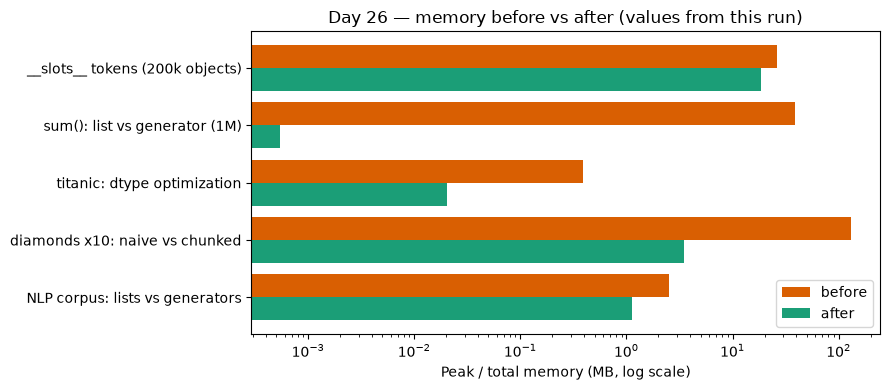

In [37]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4))
y_pos = np.arange(len(savings))
ax.barh(y_pos - 0.2, savings["before_bytes"] / 1024**2, height=0.4, label="before", color="#d95f02")
ax.barh(y_pos + 0.2, savings["after_bytes"] / 1024**2, height=0.4, label="after", color="#1b9e77")
ax.set_yticks(y_pos, savings["technique"])
ax.set_xscale("log")
ax.set_xlabel("Peak / total memory (MB, log scale)")
ax.set_title("Day 26 — memory before vs after (values from this run)")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

## 10. Checklist de boas práticas de memória para Data Science

#### Medir antes de otimizar
- [ ] Use `df.memory_usage(deep=True)` e `df.info(memory_usage="deep")` — nunca a versão rasa.
- [ ] Use `tracemalloc` (pico e *snapshots*) para descobrir **onde** a memória é alocada.
- [ ] Lembre que `sys.getsizeof` é raso; para contêineres, meça o tamanho profundo.

#### Carregar dados com inteligência
- [ ] `usecols` para ler só as colunas necessárias.
- [ ] `dtype={...}` no `read_csv` para evitar o pico `int64/float64/object`.
- [ ] `chunksize` para agregar incrementalmente quando os dados não cabem na RAM.
- [ ] Formatos colunares (Parquet) e `np.memmap` para dados muito grandes.

#### Escolher tipos adequados
- [ ] Inteiros: `pd.to_numeric(..., downcast=...)` (int8/int16/uint8...).
- [ ] Floats: `float32` quando ~7 dígitos de precisão bastam (verifique o erro!).
- [ ] Strings de baixa cardinalidade → `category` (e `observed=True` no `groupby`).
- [ ] Muitas instâncias de uma classe → `__slots__` ou `dataclass(slots=True)`.

#### Evitar cópias desnecessárias
- [ ] Prefira *views* do NumPy (*slicing*) e confirme com `np.shares_memory`.
- [ ] Operações *in-place* (`+=`, `out=`) para arrays grandes.
- [ ] Cuidado com *views* que modificam o original sem querer.
- [ ] `copy.deepcopy` só quando realmente necessário.

#### Pensar em fluxos (*streaming*)
- [ ] Geradores e `itertools` (`islice`, `batched`, `chain`, `pairwise`) em vez de listas intermediárias.
- [ ] Em NLP: tokenizar e contar em *streaming* (`Counter(gerador)`), `sys.intern` para *tokens* repetidos.
- [ ] `"".join(...)` em vez de `+=` em loops de strings.

#### Liberar memória
- [ ] `del` objetos grandes + `gc.collect()` quando houver ciclos.
- [ ] `weakref` para caches que não devem impedir a coleta.
- [ ] Em notebooks, cuidado com `Out[n]` e `_` segurando objetos.

#### Concorrência e o GIL
- [ ] Threads para I/O e para código C que libera o GIL (NumPy, muitas rotinas do scikit-learn).
- [ ] Processos para CPU-bound em Python puro — mas lembre que cada processo **copia** dados.

## Reflexão final — encerramento da Fase 1

Com este caderno, a trilha de fundamentos de Python chega ao fim do seu bloco técnico: de pandas e NumPy (Dias 1–2), passando por testes, tipagem, concorrência, empacotamento, SQL, CLIs, modelagem de dados, configuração, *design patterns*, ABCs/Protocols e APIs, até chegar ao modo como o próprio interpretador gerencia memória.

**Principais aprendizados de hoje:**
1. Variáveis são nomes que apontam para objetos; `is` ≠ `==`, e `getsizeof` é raso.
2. O CPython libera memória por contagem de referências e por um coletor cíclico geracional.
3. O GIL limita threads em código Python puro, mas não em I/O nem em boa parte do código vetorizado.
4. Escolher dtypes (`int8`, `float32`, `category`) e ler dados em *chunks* trouxe reduções grandes de memória nas medições deste caderno.
5. Para textos, pipelines de geradores permitem contar *tokens*, *types* e bigramas sem materializar o corpus — base para ferramentas de NLP aplicadas ao ensino de inglês que precisem lidar com corpora grandes de produções de alunos.

**Limitações:** as medições usam `tracemalloc`, que não enxerga todos os alocadores nativos; os valores variam entre máquinas e versões. O corpus de `DESCR` é pequeno e técnico, servindo apenas para demonstrar o padrão de processamento.

**Próximos passos (Dias 27–28):** revisão integrada da Fase 1 e preparação para a Fase 2 — Análise Exploratória de Dados.